# 13 — Build an MLP from scratch

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–12, especially autograd and in-place updates under `no_grad` (05), the training loop (06), softmax regression, `F.cross_entropy` and the initial-loss check (10), and ReLU networks (12) |
| **You will learn** | How a multilayer perceptron is built from raw tensors: every parameter, every shape, and the parameter count $\sum_\ell (n_{\ell-1} + 1)\,n_\ell$; why one batched forward pass equals $N$ separate ones; a full training loop with autograd and a manual SGD update; three debugging habits used for the rest of the course — check the initial loss, overfit a tiny batch, monitor gradient norms; what `torch.optim` needs from a model; how the same network looks as `nn.Sequential` |
| **Estimated time** | About 3 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU core well under a minute (about half of it in Exercise 4). Optional GPU section: the same code on 200,000 points. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import time

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_spirals
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

## The motivating problem

Notebook 10 trained softmax regression on three interleaved spiral arms and got stuck at about 45% training accuracy: the best three convex wedges cannot follow a spiral. Notebook 12 showed that networks of ReLU units *can* represent curved, non-convex regions. In Chapter 2 we either set such networks' weights by hand or called `nn.Sequential` and `loss.backward()` as black boxes.

Here is the data again: 300 points per arm, 900 in all.

N = 900, D = 2, K = 3; inputs range from -1.03 to 1.03


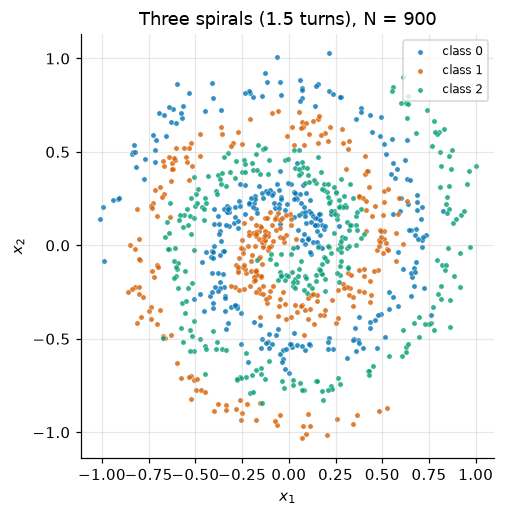

In [3]:
X_sp, y_sp = make_spirals(classes=3, seed=0)      # X_sp: (900, 2) float32, y_sp: (900,) int64 in {0, 1, 2}
N, D = X_sp.shape
K = int(y_sp.max()) + 1
print(f"N = {N}, D = {D}, K = {K}; inputs range from {X_sp.min().item():.2f} to {X_sp.max().item():.2f}")

fig, ax = plt.subplots(figsize=(5, 5))
plot_dataset(X_sp, y_sp, ax=ax, title="Three spirals (1.5 turns), N = 900")
ax.legend(loc="upper right", fontsize=8)
plt.show()

Each arm winds one and a half times around the center, so any straight line through the plane cuts every arm several times.

**This notebook builds a multilayer perceptron for this problem from raw tensors** — no `nn.Module`, no optimizer object — so that every parameter and every shape is visible. We train it with autograd, and then learn three cheap checks that tell us whether a training run is healthy *before* we spend hours on it. These habits are what make training reliable for the rest of the course.

## 1. Architecture and shapes

A **multilayer perceptron (MLP)** with $L$ layers alternates affine maps and elementwise nonlinearities. With the data $X$ of shape `(N, D)`, one example per row, and $H^{(0)} = X$:

$$A^{(\ell)} = H^{(\ell-1)} W^{(\ell)\top} + \mathbf b^{(\ell)}, \qquad H^{(\ell)} = \operatorname{relu}\big(A^{(\ell)}\big) \qquad (\ell = 1, \ldots, L-1),$$

$$Z = A^{(L)} = H^{(L-1)} W^{(L)\top} + \mathbf b^{(L)}.$$

- $n_\ell$ is the **width** of layer $\ell$: $n_0 = D$ inputs, $n_L = K$ outputs.
- $W^{(\ell)}$ has shape $(n_\ell, n_{\ell-1})$ — one row per unit of layer $\ell$, the `(out, in)` layout of `nn.Linear` — and $\mathbf b^{(\ell)}$ has shape $(n_\ell,)$.
- $A^{(\ell)}$ (the **pre-activations**) and $H^{(\ell)}$ (the **activations**) have shape $(N, n_\ell)$: row $i$ belongs to example $i$.
- The last layer has **no ReLU**: $Z$ holds the **logits**, which must be able to take any real value (a ReLU would forbid negative logits), and `F.cross_entropy` applies the log-softmax itself (notebook 10).

Without the ReLUs, the layers would collapse into one affine map (notebook 02), and we would be back to softmax regression.

### A shape table

For our network $2 \to 64 \to 64 \to 3$ on a batch of $N$ examples:

| tensor | meaning | shape | for $N = 900$ |
| --- | --- | --- | --- |
| $X = H^{(0)}$ | inputs | $(N, 2)$ | (900, 2) |
| $W^{(1)}$, $\mathbf b^{(1)}$ | layer 1 parameters | $(64, 2)$, $(64,)$ | |
| $A^{(1)}, H^{(1)}$ | layer 1 pre-activations, activations | $(N, 64)$ | (900, 64) |
| $W^{(2)}$, $\mathbf b^{(2)}$ | layer 2 parameters | $(64, 64)$, $(64,)$ | |
| $A^{(2)}, H^{(2)}$ | layer 2 pre-activations, activations | $(N, 64)$ | (900, 64) |
| $W^{(3)}$, $\mathbf b^{(3)}$ | output layer parameters | $(3, 64)$, $(3,)$ | |
| $Z$ | logits | $(N, 3)$ | (900, 3) |
| $L$ | mean cross-entropy | $()$ | scalar |

Two shape rules generate the whole table. In $H W^\top$, the shapes $(N, n_{\ell-1}) \times (n_{\ell-1}, n_\ell)$ give $(N, n_\ell)$: the inner dimensions must match. Adding $\mathbf b$ of shape $(n_\ell,)$ to an $(N, n_\ell)$ matrix **broadcasts** (notebook 01): the same bias row is added to every example.

### Counting parameters

Layer $\ell$ has $n_\ell n_{\ell-1}$ weights and $n_\ell$ biases, so

$$\#\text{parameters} = \sum_{\ell=1}^{L} (n_{\ell-1} + 1)\, n_\ell .$$

For $2 \to 64 \to 64 \to 3$: $(2+1)\cdot 64 + (64+1)\cdot 64 + (64+1)\cdot 3 = 192 + 4160 + 195 = 4547$. Most of them sit in the $64 \times 64$ middle layer: the count grows with the *product* of adjacent widths.

In [4]:
sizes = [2, 64, 64, 3]                                   # n_0, n_1, n_2, n_3
per_layer = [(n_in + 1) * n_out for n_in, n_out in zip(sizes[:-1], sizes[1:])]
print("parameters per layer:", per_layer, " total:", sum(per_layer))

parameters per layer: [192, 4160, 195]  total: 4547


We will confirm 4547 against real tensors in Section 2.

### Checkpoint 1.1

Write `count_params(sizes)` that returns the number of parameters of an MLP with layer widths `sizes = [n_0, ..., n_L]` (an `int`). Then, **by hand first**, work out the count for an MNIST-style network $784 \to 256 \to 128 \to 10$ and store your hand result in `mnist_by_hand`.

<details>
<summary><b>💡 Hint</b></summary>

Pair each width with the next one: `zip(sizes[:-1], sizes[1:])`. By hand: $785 \cdot 256 + 257 \cdot 128 + 129 \cdot 10$.

</details>

In [5]:
def count_params(sizes):
    return sum((n_in + 1) * n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))


mnist_by_hand = 785 * 256 + 257 * 128 + 129 * 10
print("count_params([784, 256, 128, 10]) =", count_params([784, 256, 128, 10]))

count_params([784, 256, 128, 10]) = 235146


In [6]:
check(count_params([2, 64, 64, 3]) == 4547, "count_params([2, 64, 64, 3]) should be 4547")
check(count_params([5, 1]) == 6, "a single layer 5 -> 1 has 5 weights and 1 bias")
check(count_params([1, 1]) == 2, "a single layer 1 -> 1 has one weight and one bias")
check(count_params([3, 1, 7]) == 4 * 1 + 2 * 7, "a bottleneck 3 -> 1 -> 7 has 4 + 14 parameters")
check(count_params([4]) == 0, "a list with a single width has no layers, hence 0 parameters")
_ref = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
_n_ref = sum(p.numel() for p in _ref.parameters())
check(count_params([784, 256, 128, 10]) == _n_ref, f"expected {_n_ref} for 784 -> 256 -> 128 -> 10")
check(mnist_by_hand == _n_ref, f"mnist_by_hand = {mnist_by_hand}, expected {_n_ref}")
passed("Checkpoint 1.1")

✅ Checkpoint 1.1 passed


## 2. Parameters as tensors

The parameters are six tensors. We draw each weight matrix from a normal distribution scaled by $1/\sqrt{n_{\ell-1}}$ (the layer's number of inputs) and start the biases at zero:

$$W^{(\ell)}_{jk} \sim \mathcal N\!\left(0, \tfrac{1}{n_{\ell-1}}\right), \qquad \mathbf b^{(\ell)} = \mathbf 0.$$

Why that scale: a pre-activation is a sum of $n_{\ell-1}$ terms, and dividing by $\sqrt{n_{\ell-1}}$ keeps its size roughly independent of the width. Notebook 18 derives the right scale properly and shows what goes wrong without it; Section 4 previews the symptom.

We keep the tensors in a dictionary, so each one has a name. The `generator` makes the initialization reproducible without touching the global random state.

In [7]:
def init_params(gen):
    """Parameters of a 2 -> 64 -> 64 -> 3 MLP: W ~ N(0, 1/n_in), b = 0. Returns a dict of leaf tensors."""
    params = {
        "W1": torch.randn(64, 2, generator=gen) / math.sqrt(2),     # (n_1, n_0)
        "b1": torch.zeros(64),                                      # (n_1,)
        "W2": torch.randn(64, 64, generator=gen) / math.sqrt(64),   # (n_2, n_1)
        "b2": torch.zeros(64),                                      # (n_2,)
        "W3": torch.randn(3, 64, generator=gen) / math.sqrt(64),    # (n_3, n_2)
        "b3": torch.zeros(3),                                       # (n_3,)
    }
    for p in params.values():
        p.requires_grad_(True)          # set AFTER scaling, so each tensor stays a leaf
    return params


params = init_params(torch.Generator().manual_seed(0))
for name, p in params.items():
    print(f"{name}: shape {tuple(p.shape)}, leaf {p.is_leaf}, requires_grad {p.requires_grad}")
print("total parameters:", sum(p.numel() for p in params.values()))

W1: shape (64, 2), leaf True, requires_grad True
b1: shape (64,), leaf True, requires_grad True
W2: shape (64, 64), leaf True, requires_grad True
b2: shape (64,), leaf True, requires_grad True
W3: shape (3, 64), leaf True, requires_grad True
b3: shape (3,), leaf True, requires_grad True
total parameters: 4547


4547, as computed by the formula. The order of the two steps matters. Had we written `torch.randn(64, 2, requires_grad=True) / math.sqrt(2)`, the division would be a recorded operation and its result a **non-leaf** tensor (notebook 05), whose `.grad` is never filled in:

In [8]:
w_wrong = torch.randn(64, 2, requires_grad=True) / math.sqrt(2)
w_wrong.sum().backward()
print("leaf:", w_wrong.is_leaf, "  .grad after backward:", w_wrong.grad)

leaf: False   .grad after backward: None


/var/folders/25/5jj7p0z14xv2nkv6vw9_xpkm0000gn/T/ipykernel_15244/494044957.py:3: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /Users/runner/work/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:493.)
  print("leaf:", w_wrong.is_leaf, "  .grad after backward:", w_wrong.grad)


(PyTorch also prints a warning about accessing `.grad` of a non-leaf.) A training loop using such a tensor would crash on `None` — or, worse, silently skip it if the loop guards with `if p.grad is not None`.

### The forward pass

The forward pass is the table of Section 1, line by line:

In [9]:
def forward(X, params):
    """Logits of the 2 -> 64 -> 64 -> 3 MLP. X: (N, 2) -> Z: (N, 3)."""
    H1 = torch.relu(X @ params["W1"].T + params["b1"])     # (N, 64)
    H2 = torch.relu(H1 @ params["W2"].T + params["b2"])    # (N, 64)
    return H2 @ params["W3"].T + params["b3"]              # (N, 3) logits, no ReLU


Z = forward(X_sp, params)
check_shape(Z, (N, K), "logits")
print("logits of the first three examples:\n", Z[:3].detach())

logits of the first three examples:
 tensor([[-0.2211, -0.1710,  0.0889],
        [-0.0929, -0.5475,  0.0986],
        [-0.0186, -0.1095,  0.0121]])


### One batch or $N$ single examples?

Nothing in the forward pass mixes rows: matrix multiplication computes row $i$ of $H W^\top$ from row $i$ of $H$ only, the bias is added row by row, and the ReLU acts elementwise. So the batched forward pass must equal $N$ separate forward passes, one per example. We check it, and time both:

In [10]:
with torch.no_grad():
    t0 = time.perf_counter()
    Z_batch = forward(X_sp, params)                                    # (N, 3), one call
    t_batch = time.perf_counter() - t0
    t0 = time.perf_counter()
    Z_loop = torch.cat([forward(X_sp[i : i + 1], params) for i in range(N)])   # N calls on (1, 2)
    t_loop = time.perf_counter() - t0
print(f"max |batched - one at a time| = {(Z_batch - Z_loop).abs().max().item():.2e}")
print(f"time: batched {1e3 * t_batch:.2f} ms, one at a time {1e3 * t_loop:.1f} ms (indicative only)")
check_close(Z_batch, Z_loop, "batched vs per-example logits")
passed("A batch of N examples = N separate forward passes")

max |batched - one at a time| = 2.38e-07
time: batched 0.39 ms, one at a time 7.0 ms (indicative only)
✅ A batch of N examples = N separate forward passes passed


The two agree to within float32 rounding (a matrix product may sum its terms in a different order for different shapes, so tiny differences are possible), and the batched version is far faster: one large matrix product instead of 900 tiny ones, each with Python and dispatch overhead (notebook 01). The batch dimension is a free "for each example" loop.

Note `X_sp[i : i + 1]` rather than `X_sp[i]`: the forward pass expects a **matrix** with one row per example, so a single example is a batch of size 1, shape `(1, 2)`.

### Checkpoint 2.1

Compute the logits `z_single` (shape `(3,)`) of example 7 **as a single vector**, without a batch dimension: start from `x = X_sp[7]` (shape `(2,)`) and use matrix–vector products $W\mathbf x + \mathbf b$. The check compares with row 7 of the batched logits.

<details>
<summary><b>💡 Hint</b></summary>

For a column-vector convention the layer is `W @ x + b`: `(64, 2) @ (2,)` gives `(64,)`. Apply `torch.relu` after the first two layers only.

</details>

In [11]:
x = X_sp[7]                                     # (2,)
with torch.no_grad():
    h1 = torch.relu(params["W1"] @ x + params["b1"])     # (64,)
    h2 = torch.relu(params["W2"] @ h1 + params["b2"])    # (64,)
    z_single = params["W3"] @ h2 + params["b3"]          # (3,)

In [12]:
check_shape(z_single, (3,), "z_single")
check_close(z_single, Z_batch[7], "z_single")
passed("Checkpoint 2.1")

✅ Checkpoint 2.1 passed


With one example per **row**, a layer is $H W^\top + \mathbf b$; with one example as a **column vector**, it is $W\mathbf x + \mathbf b$. They are the same computation — the transpose just moves to the other side.

## 3. Training from scratch

Training is the loop of notebook 06, now with six parameter tensors:

1. **Forward:** logits $Z$ of shape `(N, 3)`.
2. **Loss:** `F.cross_entropy(Z, y)` — mean categorical cross-entropy from logits and integer labels (notebook 10).
3. **Backward:** `loss.backward()` fills `p.grad` for every parameter, with the same shape as `p`. How autograd does that for an MLP is notebook 14.
4. **Update:** $p \leftarrow p - \eta\,\nabla_p L$ for each tensor, **in place** (`-=`) and inside `torch.no_grad()`, so the update itself is not recorded and `p` stays the same leaf tensor (notebook 05).
5. **Reset gradients:** `.grad` accumulates (notebook 05), so we set it to `None` before the next backward.

We train on all 900 points at once (**full-batch** gradient descent); mini-batches are notebook 19. The function takes the forward function as an argument, so we can reuse it for other models.

In [13]:
def train(forward_fn, params, X, y, lr, steps):
    """Full-batch gradient descent on the mean cross-entropy. Updates params in place.
    Returns per-step lists of the loss and the training accuracy (measured before each update)."""
    losses, accs = [], []
    for step in range(steps):
        logits = forward_fn(X, params)                  # (N, K)
        loss = F.cross_entropy(logits, y)               # () mean over the batch
        loss.backward()                                 # fills p.grad for every parameter
        with torch.no_grad():
            for p in params.values():
                p -= lr * p.grad                        # in place: p stays the same leaf tensor
                p.grad = None                           # reset, since .grad accumulates
        losses.append(loss.item())
        accs.append((logits.argmax(dim=1) == y).float().mean().item())
    return losses, accs


LR, STEPS = 0.5, 3000
params = init_params(torch.Generator().manual_seed(0))
t0 = time.perf_counter()
mlp_losses, mlp_accs = train(forward, params, X_sp, y_sp, LR, STEPS)
print(f"{STEPS} steps in {time.perf_counter() - t0:.1f} s")
with torch.no_grad():
    mlp_final_acc = (forward(X_sp, params).argmax(dim=1) == y_sp).float().mean().item()
print(f"loss: step 0 {mlp_losses[0]:.4f} (ln 3 = {math.log(3):.4f}), final {mlp_losses[-1]:.4f};  "
      f"training accuracy after training {mlp_final_acc:.3f}")

3000 steps in 1.4 s
loss: step 0 1.0886 (ln 3 = 1.0986), final 0.0844;  training accuracy after training 0.970


For comparison, the linear model of notebook 10 — softmax regression, $Z = XW^\top + \mathbf b$ — trained with exactly the same function, learning rate and number of steps:

In [14]:
def forward_linear(X, params):
    """Softmax regression: X (N, 2) -> logits (N, 3)."""
    return X @ params["W"].T + params["b"]


lin_params = {"W": torch.zeros(K, D, requires_grad=True), "b": torch.zeros(K, requires_grad=True)}
lin_losses, lin_accs = train(forward_linear, lin_params, X_sp, y_sp, LR, STEPS)
with torch.no_grad():
    lin_final_acc = (forward_linear(X_sp, lin_params).argmax(dim=1) == y_sp).float().mean().item()
print(f"linear model: final loss {lin_losses[-1]:.4f}, training accuracy {lin_final_acc:.3f}")

linear model: final loss 1.0643, training accuracy 0.453


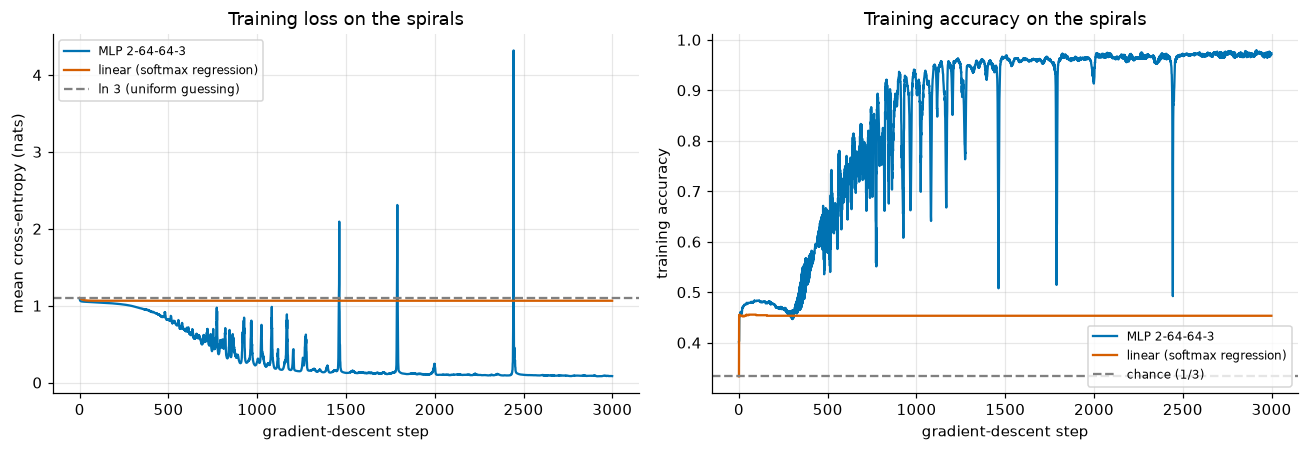

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(mlp_losses, color=COLORS[0], label="MLP 2-64-64-3")
ax1.plot(lin_losses, color=COLORS[1], label="linear (softmax regression)")
ax1.axhline(math.log(3), color="gray", ls="--", label="ln 3 (uniform guessing)")
ax1.set_xlabel("gradient-descent step")
ax1.set_ylabel("mean cross-entropy (nats)")
ax1.set_title("Training loss on the spirals")
ax1.legend(fontsize=8)
ax2.plot(mlp_accs, color=COLORS[0], label="MLP 2-64-64-3")
ax2.plot(lin_accs, color=COLORS[1], label="linear (softmax regression)")
ax2.axhline(1 / 3, color="gray", ls="--", label="chance (1/3)")
ax2.set_xlabel("gradient-descent step")
ax2.set_ylabel("training accuracy")
ax2.set_title("Training accuracy on the spirals")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Three things to notice. First, the MLP's loss starts at $\ln 3$ and sits on a **plateau** for a few hundred steps before it falls; plateaus like this are common early in training and are one reason not to judge a run by its first few steps. Second, the curve has occasional **spikes** that recover within a few steps: full-batch gradient descent with a large learning rate often oscillates like this (studied as the "edge of stability" by Cohen et al., 2021); learning rates are notebook 19's topic. Third, the linear model flattens out near $\ln 3$ and its accuracy stays far below the MLP's: the limit there is the model, not the training.

The decision regions show the difference:

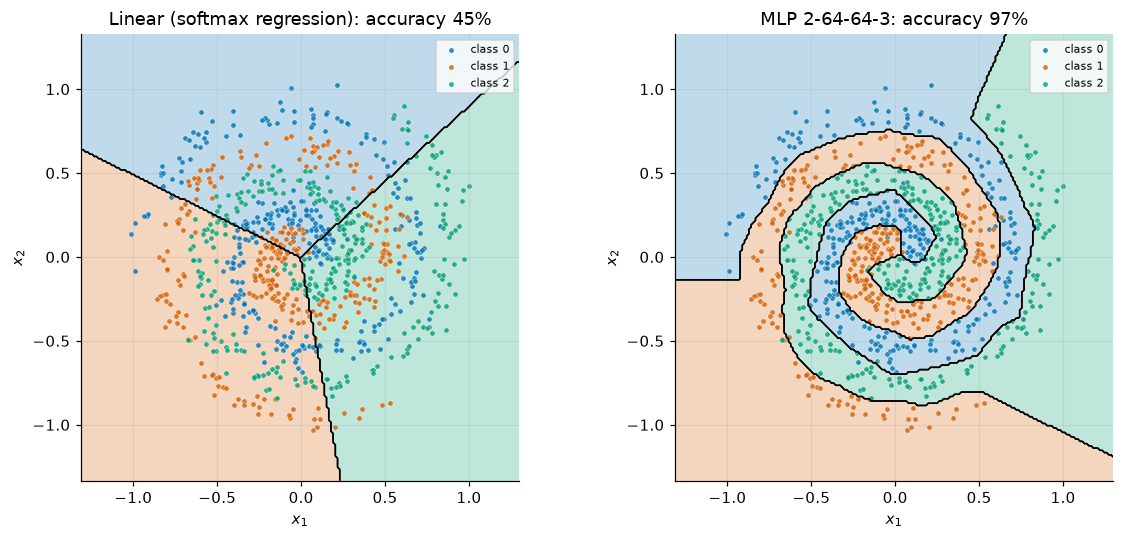

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_decision_boundary(lambda G: forward_linear(G, lin_params).argmax(dim=1), X_sp, y_sp, ax=axes[0],
                       title=f"Linear (softmax regression): accuracy {lin_final_acc:.0%}")
plot_decision_boundary(lambda G: forward(G, params).argmax(dim=1), X_sp, y_sp, ax=axes[1],
                       title=f"MLP 2-64-64-3: accuracy {mlp_final_acc:.0%}")
for ax in axes:
    ax.legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

The linear model cuts the plane into three wedges meeting at a point; the MLP's regions wind around with the arms. The few remaining errors are points that the noise has pushed close to, or into, a neighbouring arm. (This is training accuracy. Whether the regions are right *between* the training points is the question of generalization, notebook 22.)

### Checkpoint 3.1

Perform **one** gradient-descent step by hand on fresh parameters `p_ck` with learning rate 0.5: compute the loss `loss_before` (a float), backpropagate, update every tensor in place under `torch.no_grad()`, reset the gradients, and compute `loss_after` (a float) with the updated parameters. Do not call `train`.

<details>
<summary><b>💡 Hint</b></summary>

`loss = F.cross_entropy(forward(X_sp, p_ck), y_sp)`, then `loss.backward()`, then inside `with torch.no_grad():` loop over `p_ck.values()` with `p -= 0.5 * p.grad` and `p.grad = None`. Use `.item()` for the floats.

</details>

In [17]:
p_ck = init_params(torch.Generator().manual_seed(1))
loss = F.cross_entropy(forward(X_sp, p_ck), y_sp)
loss_before = loss.item()
loss.backward()
with torch.no_grad():
    for p in p_ck.values():
        p -= 0.5 * p.grad
        p.grad = None
    loss_after = F.cross_entropy(forward(X_sp, p_ck), y_sp).item()
print(f"loss before {loss_before:.5f}, after one step {loss_after:.5f}")

loss before 1.08847, after one step 1.07600


In [18]:
check(isinstance(loss_before, float) and isinstance(loss_after, float), "loss_before and loss_after should be floats")
_p = init_params(torch.Generator().manual_seed(1))
_l = F.cross_entropy(forward(X_sp, _p), y_sp)
_g = torch.autograd.grad(_l, list(_p.values()))
check_close(loss_before, _l.item(), "loss_before")
for (_name, _v), _gv in zip(_p.items(), _g):
    check_close(p_ck[_name], _v.detach() - 0.5 * _gv, f"{_name} after one step")
    check(p_ck[_name].is_leaf and p_ck[_name].requires_grad, f"{_name} should still be a leaf that requires grad")
    check(p_ck[_name].grad is None, f"{_name}.grad should be reset")
check(loss_after < loss_before, "one small step along the negative gradient should lower the loss")
passed("Checkpoint 3.1")

✅ Checkpoint 3.1 passed


## 4. Debugging habit 1: check the initial loss

The MLP's training loss started at 1.0886, close to $\ln 3 = 1.0986$. That was not luck. Notebook 10 derived the rule: if all $K$ logits of an example are equal, softmax gives each class $1/K$ and the loss is $-\ln(1/K) = \ln K$. To see how close "close" is, write the loss of example $i$ as $\ell_i = \operatorname{lse}(\mathbf z_i) - z_{i y_i}$ (log-sum-exp minus the correct logit) and expand for small logits. With $\bar z_i$ the mean and $s_i^2$ the variance of the $K$ logits of example $i$,

$$\operatorname{lse}(\mathbf z_i) = \ln K + \bar z_i + \tfrac12 s_i^2 + O(|\mathbf z_i|^3), \qquad\text{so}\qquad \ell_i \approx \ln K + (\bar z_i - z_{i y_i}) + \tfrac12 s_i^2.$$

(Derivation: $\ln\frac1K\sum_k e^{z_k} = \bar z + \ln\frac1K \sum_k e^{z_k - \bar z}$, and $e^u \approx 1 + u + u^2/2$ with $\sum_k (z_k - \bar z) = 0$.) An untrained network's logits know nothing about the labels, so the middle term averages to roughly zero over the batch — positive or negative by chance — and the last term is small when the logits are small. Hence $L \approx \ln K$, with deviations of the order of the logits' spread. Across 20 initializations:

In [19]:
init_losses, logit_spread = [], []
with torch.no_grad():
    for seed in range(20):
        Z0 = forward(X_sp, init_params(torch.Generator().manual_seed(seed)))
        init_losses.append(F.cross_entropy(Z0, y_sp).item())
        logit_spread.append(Z0.std(dim=1).mean().item())
init_losses = torch.tensor(init_losses)
print(f"initial loss over 20 seeds: mean {init_losses.mean().item():.4f}, "
      f"range {init_losses.min().item():.4f} to {init_losses.max().item():.4f};  ln 3 = {math.log(3):.4f}")
print(f"typical spread of the 3 logits of an example: {sum(logit_spread) / 20:.3f}")

initial loss over 20 seeds: mean 1.1096, range 1.0885 to 1.1660;  ln 3 = 1.0986
typical spread of the 3 logits of an example: 0.162


The three logits of an example spread by only about 0.16, and the initial loss stays within 0.07 of $\ln 3$ for every seed — mostly slightly above it, as the positive $\frac12 s_i^2$ term suggests, sometimes slightly below when the logits happen to favour the right classes. **The habit: before training, compute the loss once and compare it with $\ln K$.** It costs one forward pass.

### What a too-large initialization looks like

Multiply every weight by a factor $c > 0$ (biases are zero). The ReLU is **positively homogeneous**: $\operatorname{relu}(c\,a) = c\,\operatorname{relu}(a)$ for $c > 0$. So the first layer's activations scale by $c$, the second's by $c \cdot c$, and the logits by $c^3$ — the scale compounds with depth (notebook 18 makes this precise). Checked, together with what it does to the initial loss:

In [20]:
base = init_params(torch.Generator().manual_seed(0))
with torch.no_grad():
    Z1 = forward(X_sp, base)
    print("   c   max|Z(c) - c³ Z(1)|   logit spread   initial loss   mean max-probability   accuracy")
    for c in [0.1, 1.0, 3.0, 10.0]:
        scaled = {k: (c * v if k.startswith("W") else v) for k, v in base.items()}
        Zc = forward(X_sp, scaled)
        err = (Zc - c**3 * Z1).abs().max().item() / (c**3 * Z1.abs().max().item())
        conf = Zc.softmax(dim=1).max(dim=1).values.mean().item()
        acc_c = (Zc.argmax(dim=1) == y_sp).float().mean().item()
        print(f"{c:5.1f}   {err:12.1e} (rel.)   {Zc.std(dim=1).mean().item():10.3f}   {F.cross_entropy(Zc, y_sp).item():11.3f}"
              f"   {conf:18.3f}   {acc_c:10.3f}")

   c   max|Z(c) - c³ Z(1)|   logit spread   initial loss   mean max-probability   accuracy
  0.1        3.7e-07 (rel.)        0.000         1.099                0.333        0.402
  1.0        0.0e+00 (rel.)        0.159         1.089                0.387        0.402
  3.0        3.1e-07 (rel.)        4.293         3.827                0.868        0.402
 10.0        3.9e-07 (rel.)      159.000       135.368                0.982        0.402


The logits scale exactly by $c^3$ (to float32 rounding). With $c = 10$ the logits of an example spread by about 160, the network puts on average 98% of its probability on one class — and since it knows nothing yet, that class is wrong for 60% of the examples — and the initial loss is over a hundred times $\ln 3$. Each confidently wrong example costs roughly its logit gap $\max_k z_{ik} - z_{iy_i}$ (notebook 10, Exercise 4).

Notice the last column: the **accuracy is identical** for every $c$, because multiplying all logits by a positive number does not change which one is largest. Accuracy at initialization would never reveal this problem; the loss does. With $c = 0.1$ the opposite happens: the loss is almost exactly $\ln 3$, but the logits are tiny — Section 6 shows why that is a problem of its own.

### What the check assumes

"$L \approx \ln K$" is not a theorem about untrained networks. It follows from one assumption: **the initial logits of each example are approximately equal** (small, or at least uninformative and close together). The table is already one counterexample: the $c = 3$ network has no bug at all, yet starts at 3.8, because its random logits are not small. A second counterexample goes the other way. With **imbalanced classes**, a model whose output bias matches the log class frequencies starts *below* $\ln K$, legitimately: its loss is the entropy of the label distribution. A control on a subset of the spirals with 300, 60 and 60 examples per class:

In [21]:
keep = torch.cat([torch.nonzero(y_sp == k).squeeze(1)[:n_k] for k, n_k in enumerate([300, 60, 60])])
y_imb = y_sp[keep]                                                   # (420,) imbalanced labels
freq_imb = torch.bincount(y_imb, minlength=K).float() / len(y_imb)   # (3,) class frequencies
Z_zero = torch.zeros(len(y_imb), K)                                  # equal logits
Z_prior = torch.log(freq_imb).expand(len(y_imb), K)                  # bias = log class frequencies, no input dependence
entropy = -(freq_imb * torch.log(freq_imb)).sum().item()
print(f"class frequencies {[round(v, 3) for v in freq_imb.tolist()]}")
print(f"equal logits:          loss {F.cross_entropy(Z_zero, y_imb).item():.4f}  (ln 3 = {math.log(3):.4f})")
print(f"log-frequency logits:  loss {F.cross_entropy(Z_prior, y_imb).item():.4f}  (entropy of the labels = {entropy:.4f})")

class frequencies [0.714, 0.143, 0.143]
equal logits:          loss 1.0986  (ln 3 = 1.0986)
log-frequency logits:  loss 0.7963  (entropy of the labels = 0.7963)


Equal logits give exactly $\ln 3$; logits equal to the log frequencies give the label entropy, 0.80, well below $\ln 3$ without any bug. So read the check as: *with an initialization that makes the logits nearly equal*, a loss far above $\ln K$ means the logits are not what you think (scale, inputs, loss on the wrong tensor), and a loss far below it is suspicious unless the classes are imbalanced and the output bias encodes their frequencies. It is a cheap sanity check that points where to look, not proof of a bug.

### Checkpoint 4.1

1. A 4-layer ReLU MLP (three hidden layers, zero biases) has every weight multiplied by 2. By what factor are its logits multiplied? Store it in `logit_factor`.
2. Store in `expected_init_loss` the initial loss you expect for a well-initialized 10-class classifier (a float).

<details>
<summary><b>💡 Hint</b></summary>

Each of the 4 weight matrices contributes one factor of 2, because the ReLUs pass the factor through. The second answer is $\ln K$.

</details>

In [22]:
logit_factor = 2**4
expected_init_loss = math.log(10)

In [23]:
_g = torch.Generator().manual_seed(3)
_Ws = [torch.randn(o, i, generator=_g) / math.sqrt(i) for i, o in [(2, 16), (16, 16), (16, 16), (16, 10)]]


def _f(X, s):
    H = X
    for k, W in enumerate(_Ws):
        H = H @ (s * W).T
        H = torch.relu(H) if k < len(_Ws) - 1 else H
    return H


_r = _f(X_sp, 2.0) / _f(X_sp, 1.0)
check_close(float(logit_factor), _r[_f(X_sp, 1.0).abs() > 1e-3].mean().item(), "logit_factor", rtol=1e-3)
check_close(expected_init_loss, F.cross_entropy(torch.zeros(5, 10), torch.arange(5)).item(), "expected_init_loss")
passed("Checkpoint 4.1")

✅ Checkpoint 4.1 passed


## 5. Debugging habit 2: overfit a tiny batch

Our network has 4547 parameters. Take only **12** training examples. There are far more parameters than constraints, and a correctly built network should drive the training loss on those 12 examples to (nearly) zero within a few hundred steps: it can simply memorize them. If it cannot, something is broken — in the model, the loss, the labels, the update — and the problem is *not* "the model is too small", "the data are too hard" or "it needs to generalize better", the explanations one reaches for when a full training run disappoints. The test takes seconds.

In [24]:
idx_tiny = torch.randperm(N, generator=torch.Generator().manual_seed(0))[:12]
X_tiny, y_tiny = X_sp[idx_tiny], y_sp[idx_tiny]            # (12, 2), (12,)
print("labels of the tiny batch:", y_tiny.tolist())

p_tiny = init_params(torch.Generator().manual_seed(0))
tiny_losses, tiny_accs = train(forward, p_tiny, X_tiny, y_tiny, lr=0.5, steps=500)
print(f"tiny batch: loss {tiny_losses[0]:.4f} -> {tiny_losses[-1]:.4f}, final accuracy {tiny_accs[-1]:.2f}")

labels of the tiny batch: [0, 2, 2, 2, 1, 0, 1, 2, 2, 0, 2, 0]
tiny batch: loss 1.0995 -> 0.0034, final accuracy 1.00


The loss falls from $\ln 3$ to a few thousandths: the pipeline can learn.

### A planted bug

A common preprocessing step is to **standardize** the features: subtract each feature's mean and divide by its standard deviation (notebook 06). Here it is written with the wrong `dim` — a reduction over the two features of each *example* instead of over the examples of each *feature*:

In [25]:
def standardize_buggy(X):
    return (X - X.mean(dim=1, keepdim=True)) / X.std(dim=1, keepdim=True)    # BUG: dim=1


def standardize(X):
    return (X - X.mean(dim=0)) / X.std(dim=0)                                 # per feature, over examples


p_bug = init_params(torch.Generator().manual_seed(0))
bug_losses, bug_accs = train(forward, p_bug, standardize_buggy(X_sp), y_sp, lr=LR, steps=STEPS)
print(f"full data with the bug: final loss {bug_losses[-1]:.4f}, training accuracy {bug_accs[-1]:.3f}")

full data with the bug: final loss 1.0833, training accuracy 0.399


Nothing crashes. The loss goes down a little and the accuracy (about 40%) is above chance. Seen in isolation, this run looks like a model that is too small or a learning rate that is too low, and one could spend a day tuning them. The tiny-batch test settles it in seconds:

In [26]:
p_bug_tiny = init_params(torch.Generator().manual_seed(0))
bug_tiny_losses, _ = train(forward, p_bug_tiny, standardize_buggy(X_tiny), y_tiny, lr=0.5, steps=500)
p_fix_tiny = init_params(torch.Generator().manual_seed(0))
fix_tiny_losses, _ = train(forward, p_fix_tiny, standardize(X_tiny), y_tiny, lr=0.5, steps=500)
print(f"tiny batch, buggy standardization: final loss {bug_tiny_losses[-1]:.4f}")
print(f"tiny batch, fixed standardization: final loss {fix_tiny_losses[-1]:.4f}")
print("buggy standardized inputs:\n", standardize_buggy(X_tiny)[:4])

tiny batch, buggy standardization: final loss 0.9818
tiny batch, fixed standardization: final loss 0.0013
buggy standardized inputs:
 tensor([[-0.7071,  0.7071],
        [ 0.7071, -0.7071],
        [-0.7071,  0.7071],
        [ 0.7071, -0.7071]])


A 4547-parameter network cannot fit 12 points: something destroys information. The printout shows what. Each row has only two numbers; subtracting their mean leaves $\pm\frac{x_1 - x_2}{2}$, and dividing by their standard deviation $\frac{|x_1 - x_2|}{\sqrt 2}$ leaves exactly $\pm(\tfrac{1}{\sqrt2}, -\tfrac{1}{\sqrt2})$. **Every input becomes one of two points**, so the network sees only "is $x_1 > x_2$?".

We can even predict where the loss gets stuck. If the inputs take only two distinct values, the best any model can do is to predict, for each of the two input values, the label frequencies of the examples that share it; the minimal mean cross-entropy is then the average surprise of each label under those frequencies (maximum likelihood for a categorical, notebook 04).

In [27]:
groups = standardize_buggy(X_tiny)[:, 0] > 0                  # which of the two points each example became
floor = 0.0
for g in [True, False]:
    labels_g = y_tiny[groups == g]
    freq = torch.bincount(labels_g, minlength=K).float() / len(labels_g)     # best predicted distribution
    floor += -torch.log(freq[labels_g]).sum().item()
    print(f"group {'x1 > x2' if g else 'x1 < x2'}: labels {labels_g.tolist()}")
floor /= len(y_tiny)
print(f"lowest achievable loss with two distinct inputs: {floor:.4f};  reached: {bug_tiny_losses[-1]:.4f}")

group x1 > x2: labels [2, 2, 1, 2, 0]
group x1 < x2: labels [0, 2, 1, 0, 2, 2, 0]
lowest achievable loss with two distinct inputs: 0.9818;  reached: 0.9818


The buggy run stops exactly at the floor that the collapsed inputs allow (to four digits), and no amount of training or width can get past it. The fixed version reaches nearly zero.

**A failure is evidence, not proof.** The test assumes the optimizer is given a fair chance: a reasonable learning rate, enough steps, distinct inputs. A correct pipeline with a learning rate 100 times smaller fails it too — a negative control:

In [28]:
p_slow = init_params(torch.Generator().manual_seed(0))
slow_losses, _ = train(forward, p_slow, X_tiny, y_tiny, lr=0.005, steps=500)
print(f"tiny batch, correct code, lr = 0.005: loss {slow_losses[0]:.4f} -> {slow_losses[-1]:.4f}")

tiny batch, correct code, lr = 0.005: loss 1.0995 -> 0.8695


No bug, and after 500 steps the loss is still 0.87, nowhere near zero. Before blaming the code, rerun with a larger learning rate or more steps; the planted bug above fails at *any* learning rate, because the floor is a property of the data the model sees.

**What the test does and does not catch.** It catches bugs that destroy information or stop learning: collapsed inputs, labels that do not match their inputs from one step to the next, an update that never changes the parameters (Exercise 3), a sign error. It does *not* catch bugs that merely reduce capacity, because a large network can memorize 12 points even with a handicap. For example, freezing the first layer by detaching its output still passes:

In [29]:
def forward_detached(X, params):
    H1 = torch.relu(X @ params["W1"].T + params["b1"]).detach()   # BUG: first layer gets no gradient
    H2 = torch.relu(H1 @ params["W2"].T + params["b2"])
    return H2 @ params["W3"].T + params["b3"]


p_det = init_params(torch.Generator().manual_seed(0))
loss = None
for step in range(500):
    loss = F.cross_entropy(forward_detached(X_tiny, p_det), y_tiny)
    loss.backward()
    with torch.no_grad():
        for p in p_det.values():
            if p.grad is not None:              # W1 and b1 never receive a gradient
                p -= 0.5 * p.grad
                p.grad = None
print(f"tiny batch with a detached first layer: final loss {loss.item():.4f};  W1.grad is {p_det['W1'].grad}")

tiny batch with a detached first layer: final loss 0.0138;  W1.grad is None


Its loss still drops to about 0.01. That bug is caught instead by habit 3: a parameter whose gradient is `None` or exactly zero.

### Checkpoint 5.1

Six examples are collapsed by a bug into two distinct inputs: the first three examples, with labels $(0, 0, 1)$, become point A; the last three, with labels $(2, 2, 2)$, become point B. By hand, what is the lowest mean cross-entropy any model can reach on these six examples? Store it in `floor_small` (a float).

<details>
<summary><b>💡 Hint</b></summary>

At A the best prediction is $(\frac23, \frac13, 0)$; at B it is $(0, 0, 1)$. The total surprise is $2 \cdot(-\ln\frac23) + (-\ln\frac13) + 3 \cdot 0$; divide by 6.

</details>

In [30]:
floor_small = (2 * -math.log(2 / 3) - math.log(1 / 3)) / 6
print(f"floor_small = {floor_small:.4f}")

floor_small = 0.3183


In [31]:
_counts = torch.tensor([2.0, 1.0, 0.0])                            # labels at point A; point B is all class 2
_freq = _counts / _counts.sum()
_nll_A = -(_counts[:2] * torch.log(_freq[:2])).sum()                # surprise of A's labels under its frequencies
check_close(floor_small, (_nll_A / 6).item(), "floor_small")
passed("Checkpoint 5.1")

✅ Checkpoint 5.1 passed


## 6. Debugging habit 3: monitor gradient norms

After each `backward()`, every parameter tensor has a gradient of its own shape. Its **norm** $\|\nabla_{W^{(\ell)}} L\|$ (the square root of the sum of squared entries) summarizes how strongly the loss is pulling on that tensor. Recording it for each tensor during training costs almost nothing and shows problems that the loss alone hides. We record it for two runs: our healthy run, and the same network initialized with $c = 0.1$ (Section 4).

In [32]:
def train_with_grad_norms(params, X, y, lr, steps):
    """Like train(), but also records the gradient norm of every parameter tensor at every step."""
    losses, norms = [], {name: [] for name in params}
    for step in range(steps):
        loss = F.cross_entropy(forward(X, params), y)
        loss.backward()
        with torch.no_grad():
            for name, p in params.items():
                norms[name].append(p.grad.norm().item())
                p -= lr * p.grad
                p.grad = None
        losses.append(loss.item())
    return losses, norms


runs = {}
for label, c in [("healthy (c = 1)", 1.0), ("too small (c = 0.1)", 0.1)]:
    p_run = init_params(torch.Generator().manual_seed(0))
    with torch.no_grad():
        for name in ["W1", "W2", "W3"]:
            p_run[name] *= c
    runs[label] = train_with_grad_norms(p_run, X_sp, y_sp, LR, STEPS)

for label, (losses_r, norms_r) in runs.items():
    print(label)
    print("   step     loss    " + "  ".join(f"{name:>8s}" for name in norms_r))
    for s in [0, 100, 1000, 2999]:
        print(f"   {s:4d}   {losses_r[s]:.4f}   " + "  ".join(f"{norms_r[name][s]:8.1e}" for name in norms_r))

healthy (c = 1)
   step     loss          W1        b1        W2        b2        W3        b3
      0   1.0886    1.7e-02   3.3e-02   1.1e-01   4.5e-02   9.9e-02   6.3e-02
    100   1.0424    2.7e-03   6.2e-03   8.7e-03   5.4e-03   8.3e-03   5.0e-04
   1000   0.2789    9.2e-02   3.8e-01   5.2e-01   3.7e-01   2.8e-01   1.0e-01
   2999   0.0844    4.9e-02   1.6e-01   1.3e-01   8.9e-02   6.1e-02   1.3e-02
too small (c = 0.1)
   step     loss          W1        b1        W2        b2        W3        b3
      0   1.0986    2.3e-04   3.8e-04   1.2e-03   3.6e-03   1.1e-03   6.3e-05
    100   1.0982    6.6e-04   1.2e-03   2.6e-03   1.3e-03   2.6e-03   9.0e-05
   1000   1.0476    2.5e-03   1.8e-03   3.5e-03   9.9e-04   2.7e-03   5.0e-04
   2999   0.2254    1.7e-01   3.9e-01   2.8e-01   1.8e-01   1.7e-01   1.8e-02


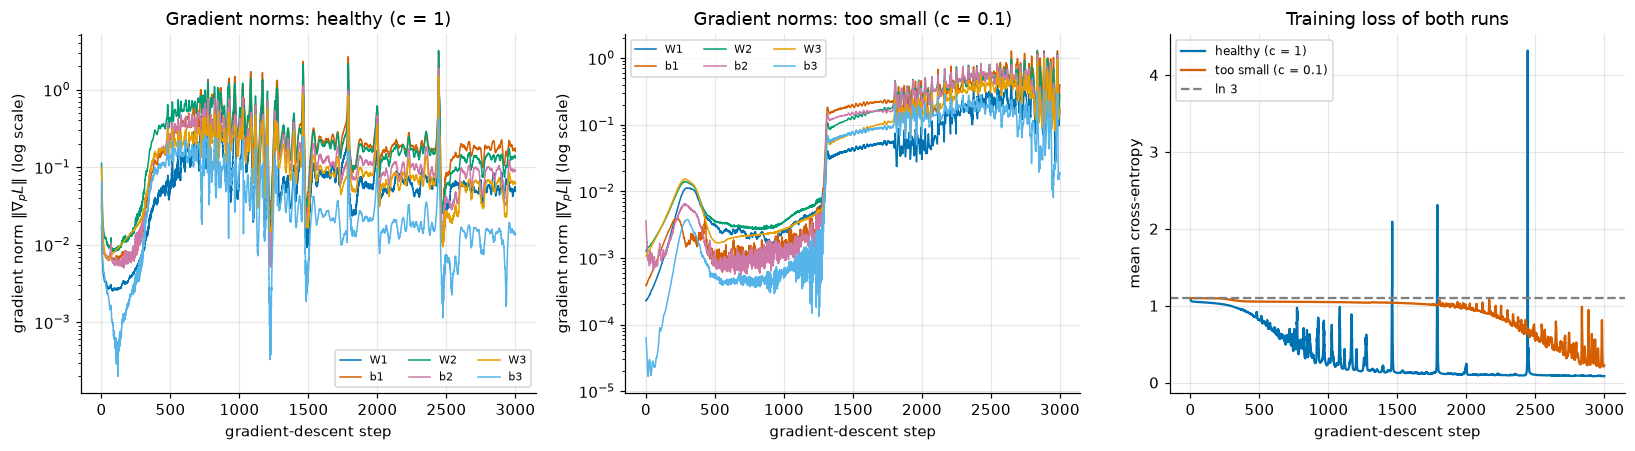

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (label, (losses_r, norms_r)) in zip(axes[:2], runs.items()):
    for k, (name, values) in enumerate(norms_r.items()):
        ax.semilogy(values, color=COLORS[k], lw=1, label=name)
    ax.set_xlabel("gradient-descent step")
    ax.set_ylabel("gradient norm $\\|\\nabla_p L\\|$ (log scale)")
    ax.set_title(f"Gradient norms: {label}")
    ax.legend(fontsize=7, ncol=3)
for k, (label, (losses_r, _)) in enumerate(runs.items()):
    axes[2].plot(losses_r, color=COLORS[k], label=label)
axes[2].axhline(math.log(3), color="gray", ls="--", label="ln 3")
axes[2].set_xlabel("gradient-descent step")
axes[2].set_ylabel("mean cross-entropy")
axes[2].set_title("Training loss of both runs")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Healthy run (left).** All six gradient norms stay within about two orders of magnitude of each other, change smoothly, and are never zero, `inf` or `nan`. They shrink during the plateau, grow when the network starts to learn, and spike together with the loss spikes of Section 3 before settling again. A short spike that recovers is benign.

**Initialization too small (middle).** With weights scaled by 0.1 the logits are scaled by $10^{-3}$. Almost every gradient starts about two orders of magnitude smaller than in the healthy run (the table: $\|\nabla_{W^{(1)}}L\| \approx 2 \times 10^{-4}$ instead of $2 \times 10^{-2}$). A weight gradient is a product of the activations entering the layer — small, because of the small weights below — and of the signal arriving from the loss — small, because it passes through the small weights above (notebook 14 derives this). The norms stay around $10^{-3}$ for over a thousand steps; the loss (right) barely moves below $\ln 3$ for nearly 2000 steps and after 3000 steps is at 0.23, where the healthy run reached 0.08. The loss curve alone would just say "slow"; the gradient norms say *why*.

These are heuristics, not proofs. A tiny gradient can be legitimate: with $c = 0.1$ the output bias's gradient, $\nabla_{\mathbf b^{(3)}} L = \frac1N\sum_i(\mathbf p_i - \mathbf y_i)$ (notebook 10), is about $6 \times 10^{-5}$ simply because the predictions are all near $\frac13$ and the classes are balanced, so the average residual is nearly zero. Compare norms across tensors and over time, and confirm a suspicion with a direct test before calling it a bug.

What to look for, in short (notebook 18 treats it fully):

- a gradient that is `None` or exactly 0: that tensor is not connected to the loss (the detached layer of Section 5);
- `inf` or `nan`: overflow, usually from a too-large learning rate or initialization;
- one layer orders of magnitude below the others, or all norms tiny: vanishing gradients;
- norms that grow step after step instead of spiking and recovering: divergence.

### Checkpoint 6.1

Write `grad_norms(params)` that returns a dictionary mapping each parameter name to the norm of its gradient as a Python float, or to `None` if the gradient is `None`. Keep the two cases apart: a gradient that exists and is exactly zero has norm `0.0`. The check runs it after one backward pass of the detached model of Section 5, and on a gradient that is exactly zero.

<details>
<summary><b>💡 Hint</b></summary>

A dictionary comprehension: `{name: (p.grad.norm().item() if p.grad is not None else None) for name, p in params.items()}`.

</details>

In [34]:
def grad_norms(params):
    return {name: (p.grad.norm().item() if p.grad is not None else None) for name, p in params.items()}

In [35]:
_p = init_params(torch.Generator().manual_seed(2))
F.cross_entropy(forward_detached(X_sp, _p), y_sp).backward()
_gn = grad_norms(_p)
check(isinstance(_gn, dict) and set(_gn) == set(_p), "grad_norms should return a dict with one entry per parameter")
check(_gn["W1"] is None and _gn["b1"] is None, "W1 and b1 receive no gradient in the detached model: expected None")
for _name in ["W2", "b2", "W3", "b3"]:
    check(isinstance(_gn[_name], float), f"{_name}: expected a Python float")
    check_close(_gn[_name], _p[_name].grad.norm().item(), f"norm of {_name}.grad")
_z = {"a": torch.zeros(2, 3, requires_grad=True), "b": torch.ones(1, requires_grad=True)}
(0 * _z["a"].sum() + 2 * _z["b"].sum()).backward()                 # a: gradient exactly zero, not None
_gz = grad_norms(_z)
check(_gz["a"] == 0.0, f"a zero gradient should give norm 0.0 (not None), got {_gz['a']}")
check_close(_gz["b"], 2.0, "norm of a (1,) gradient")
passed("Checkpoint 6.1")

✅ Checkpoint 6.1 passed


## 7. What an optimizer needs, and the same network as `nn.Sequential`

Our update loop is three lines. `torch.optim.SGD` does the same thing; what does it need from a "model"? Only an **iterable of tensors** that are leaves with `requires_grad=True`. `step()` reads each tensor's `.grad` and updates the tensor in place; `zero_grad()` resets the `.grad`s (to `None`, by default). It never sees the forward pass. A tiny class with a `__call__` and a `parameters()` method is therefore enough to look like a PyTorch model to an optimizer:

In [36]:
class TinyMLP:
    """Our 2 -> 64 -> 64 -> 3 MLP wrapped like a model: call it on X, ask for its parameters."""

    def __init__(self, gen):
        self.params = init_params(gen)

    def __call__(self, X):
        return forward(X, self.params)

    def parameters(self):
        return list(self.params.values())


model = TinyMLP(torch.Generator().manual_seed(0))
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
print("the optimizer holds the very same tensor objects:",
      all(a is b for a, b in zip(optimizer.param_groups[0]["params"], model.parameters())))

reference = init_params(torch.Generator().manual_seed(0))     # same initialization, trained by our loop
train(forward, reference, X_sp, y_sp, LR, 200)
for step in range(200):
    optimizer.zero_grad()
    loss = F.cross_entropy(model(X_sp), y_sp)
    loss.backward()
    optimizer.step()
diff = max((model.params[name] - reference[name]).abs().max().item() for name in reference)
print(f"after 200 steps, max |torch.optim.SGD - our loop| over all parameters = {diff:.1e}")
check_close(diff, 0.0, "parameter difference", atol=1e-6)
passed("torch.optim.SGD reproduces the manual update")

the optimizer holds the very same tensor objects: True
after 200 steps, max |torch.optim.SGD - our loop| over all parameters = 0.0e+00
✅ torch.optim.SGD reproduces the manual update passed


Both computations perform the same floating-point operations in the same order, so the parameters agree exactly (or to the last bit). Because the optimizer holds *references* to our tensors, it updates `model.params` directly. This is also why an optimizer silently ignores any tensor not in the iterable it was given — a bug the chapter problem set returns to.

### The same network as `nn.Sequential`

`nn.Linear(n_in, n_out)` stores a weight of shape `(n_out, n_in)` — our layout — and a bias `(n_out,)`, and computes $XW^\top + \mathbf b$. So `nn.Sequential` with three `nn.Linear` layers and two `nn.ReLU`s is our network. Copy our trained weights in and compare outputs:

In [37]:
seq = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 3))
print(seq)
with torch.no_grad():
    for layer, k in zip([seq[0], seq[2], seq[4]], [1, 2, 3]):
        layer.weight.copy_(params[f"W{k}"])          # params: the network trained in Section 3
        layer.bias.copy_(params[f"b{k}"])
    Z_seq, Z_ours = seq(X_sp), forward(X_sp, params)
print("parameter shapes:", [tuple(p.shape) for p in seq.parameters()])
print("number of parameters:", sum(p.numel() for p in seq.parameters()))
print(f"max |nn.Sequential - forward| = {(Z_seq - Z_ours).abs().max().item():.1e}")
check_close(Z_seq, Z_ours, "nn.Sequential logits", rtol=1e-4, atol=1e-4)
check(torch.equal(Z_seq.argmax(dim=1), Z_ours.argmax(dim=1)), "the predicted classes should be identical")
passed("nn.Sequential with copied weights = our MLP")

Sequential(
  (0): Linear(in_features=2, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=3, bias=True)
)
parameter shapes: [(64, 2), (64,), (64, 64), (64,), (3, 64), (3,)]
number of parameters: 4547
max |nn.Sequential - forward| = 7.6e-06
✅ nn.Sequential with copied weights = our MLP passed


Same six shapes, same 4547 parameters, same logits up to float32 rounding (`nn.Linear` computes the product and the bias in a single fused operation, which can round differently in the last bit), and identical predictions. What `nn.Module` adds — registering parameters automatically, nesting, `state_dict`, train/eval modes, hooks — is notebook 15. Note that `nn.Linear` has its *own* default initialization (uniform, with nonzero biases), so a freshly constructed `nn.Sequential` is not the same network as `init_params` until we copy weights.

### Checkpoint 7.1

The reverse direction: given the randomly initialized `seq_ref` below, build a dictionary `params_from_seq` with keys `"W1"`, `"b1"`, …, `"b3"` such that `forward(X_sp, params_from_seq)` equals `seq_ref(X_sp)`.

<details>
<summary><b>💡 Hint</b></summary>

The `nn.Linear` layers are at indices 0, 2 and 4 of the `nn.Sequential`. Their tensors are `.weight` and `.bias`; you can use them directly (or `.detach().clone()` them).

</details>

In [38]:
torch.manual_seed(5)
seq_ref = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 3))
params_from_seq = {}
for k, i in zip([1, 2, 3], [0, 2, 4]):
    params_from_seq[f"W{k}"] = seq_ref[i].weight.detach().clone()
    params_from_seq[f"b{k}"] = seq_ref[i].bias.detach().clone()

In [39]:
check(isinstance(params_from_seq, dict) and set(params_from_seq) == {"W1", "b1", "W2", "b2", "W3", "b3"},
      "params_from_seq should have keys W1, b1, W2, b2, W3, b3")
with torch.no_grad():
    check_close(forward(X_sp, params_from_seq), seq_ref(X_sp), "forward(X_sp, params_from_seq)")
passed("Checkpoint 7.1")

✅ Checkpoint 7.1 passed


## 8. [GPU] The same code on 200,000 points

Nothing in `init_params`, `forward` or the update depends on where the tensors live. Moving the parameters and the data to `device` with `.to(device)` runs the identical code on a GPU. We train the same MLP for 500 full-batch steps on a spirals dataset with about 200,000 points, once on the CPU and once on `device`, from the same initialization, and compare the loss curves. Floating-point operations are executed in different orders on different hardware, so the results agree only up to rounding; the timing is indicative only (Chapter 5 measures GPU performance properly).

In [40]:
if device.type == "cpu":
    print("No GPU selected; skipping. (On Colab, choose a GPU runtime to try this.)")
else:
    X_big, y_big = make_spirals(n=66_667, classes=3, seed=1)        # (200001, 2), (200001,)

    def run_on(dev, steps=500):
        p_dev = {k: v.detach().to(dev).requires_grad_(True) for k, v in init_params(torch.Generator().manual_seed(0)).items()}
        X_dev, y_dev = X_big.to(dev), y_big.to(dev)
        losses_dev = []
        sync = torch.cuda.synchronize if dev.type == "cuda" else (torch.mps.synchronize if dev.type == "mps" else (lambda: None))
        sync()
        t0 = time.perf_counter()
        for step in range(steps):
            loss = F.cross_entropy(forward(X_dev, p_dev), y_dev)
            loss.backward()
            with torch.no_grad():
                for p in p_dev.values():
                    p -= LR * p.grad
                    p.grad = None
            losses_dev.append(loss.detach())                       # stays on the device: no sync per step
        sync()
        return torch.stack(losses_dev).cpu(), time.perf_counter() - t0

    losses_cpu, t_cpu = run_on(torch.device("cpu"))
    losses_dev, t_dev = run_on(device)
    print(f"N = {len(X_big)}: final loss CPU {losses_cpu[-1].item():.5f}, {device.type} {losses_dev[-1].item():.5f}")
    print(f"max |loss difference| over 500 steps: {(losses_cpu - losses_dev).abs().max().item():.1e}")
    print(f"time: CPU {t_cpu:.1f} s, {device.type} {t_dev:.1f} s (indicative only)")
    check_close(losses_dev[-1], losses_cpu[-1], "final loss on device vs CPU", rtol=0, atol=1e-2)
    passed("Same code, same result on CPU and GPU")

N = 200001: final loss CPU 0.74220, mps 0.74202
max |loss difference| over 500 steps: 3.0e-03
time: CPU 16.0 s, mps 10.0 s (indicative only)
✅ Same code, same result on CPU and GPU passed


The final losses agree to about three decimal places. They are not bitwise equal: the two devices round differently, and those tiny differences grow over 500 steps of training (especially through the loss spikes of Section 3), so a tolerance is the right way to compare. How much faster the device is depends heavily on the hardware and on the layer sizes: with 64-unit layers the matrices are small, and a GPU shines only when there is enough work per operation to keep it busy — the subject of Chapter 5.

## Exercises

### Exercise 1 (modify): width, depth and learning rate

The cell below trains an MLP on the spirals for `steps` full-batch steps with the hidden widths in `hidden` and learning rate `lr`. It builds the network with `nn.Sequential` and `torch.optim.SGD` (equivalent to our raw-tensor version, Section 7), re-initialized with our scale $1/\sqrt{n_{\ell-1}}$ and zero biases. It prints the initial and final loss and accuracy and shows the decision regions and loss curve.

Run it once as given, then change one thing at a time and describe what changes:

1. **Width:** `hidden = [8, 8]` and `hidden = [256, 256]`.
2. **Depth:** `hidden = [64]` and `hidden = [64, 64, 64, 64]`.
3. **Learning rate:** `lr = 0.05` and `lr = 2.0` with `hidden = [64, 64]`.

Answer in the markdown cell below: which settings fit the spirals within 3000 steps, which do not, and — using the loss curve — whether each failure is a matter of *capacity* or of *training*.

<details>
<summary><b>💡 Hint</b></summary>

A model that lacks capacity has a loss curve that flattens out at a high value. A model that is training slowly has a curve that is still clearly going down at the last step. Also check the initial loss: does it stay near $\ln 3$ for every architecture?

</details>

hidden = [64, 64], lr = 0.5: 4547 parameters, loss 1.112 -> 0.091, training accuracy 0.977


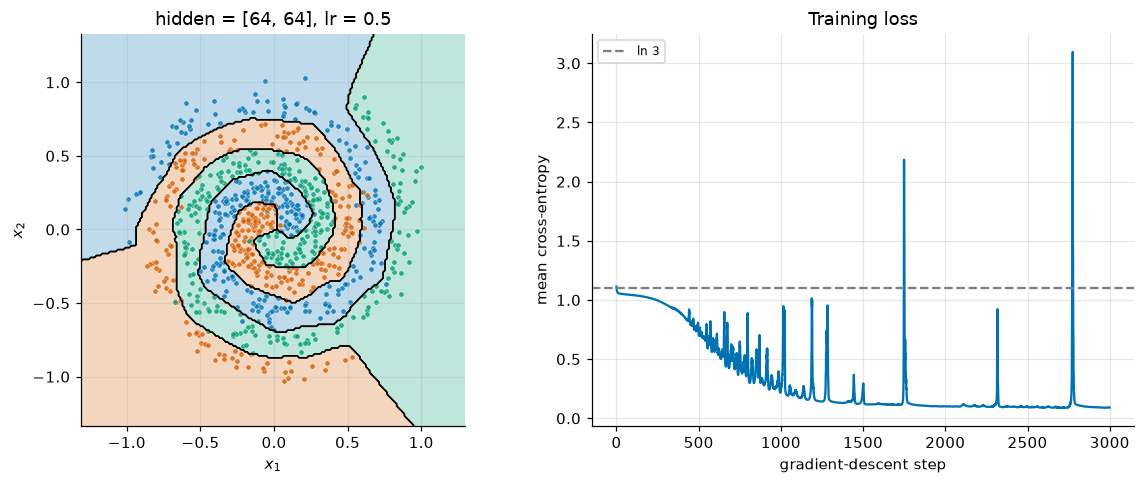

In [41]:
hidden, lr, steps = [64, 64], 0.5, 3000


def make_mlp(sizes, seed):
    torch.manual_seed(seed)
    layers = []
    for k, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        linear = nn.Linear(n_in, n_out)
        with torch.no_grad():
            linear.weight.normal_(0, 1 / math.sqrt(n_in))
            linear.bias.zero_()
        layers.append(linear)
        if k < len(sizes) - 2:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)


net = make_mlp([2, *hidden, 3], seed=0)
opt = torch.optim.SGD(net.parameters(), lr=lr)
ex1_losses = []
for step in range(steps):
    opt.zero_grad()
    loss = F.cross_entropy(net(X_sp), y_sp)
    loss.backward()
    opt.step()
    ex1_losses.append(loss.item())
with torch.no_grad():
    acc_ex1 = (net(X_sp).argmax(dim=1) == y_sp).float().mean().item()
print(f"hidden = {hidden}, lr = {lr}: {sum(p.numel() for p in net.parameters())} parameters, "
      f"loss {ex1_losses[0]:.3f} -> {ex1_losses[-1]:.3f}, training accuracy {acc_ex1:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
plot_decision_boundary(lambda G: net(G).argmax(dim=1), X_sp, y_sp, ax=ax1, title=f"hidden = {hidden}, lr = {lr}")
ax2.plot(ex1_losses, color=COLORS[0])
ax2.axhline(math.log(3), color="gray", ls="--", label="ln 3")
ax2.set_xlabel("gradient-descent step")
ax2.set_ylabel("mean cross-entropy")
ax2.set_title("Training loss")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

*Your answer:*

> **Worked solution.**
>
> **Baseline** (`[64, 64]`, $\eta = 0.5$): loss 1.112 → 0.091, training accuracy 0.977, regions following the arms. Every architecture starts near $\ln 3$ (1.08–1.14): the $1/\sqrt{n_{\ell-1}}$ scale keeps the initial logits small whatever the width or depth.
>
> **Width.** `[8, 8]` (123 parameters) ends at loss 0.72 and accuracy 0.72; its curve is still creeping down. `[256, 256]` (67,331 parameters) ends where the baseline does (loss 0.082, accuracy 0.967) but gets there faster (loss 0.46 at step 500, versus 0.71). Is the narrow net short of capacity or of training? Running it 10× longer (30,000 steps) brings it only to loss 0.39 and accuracy 0.83: mostly capacity — 8 units per layer cannot draw enough pieces of boundary.
>
> **Depth.** `[64]` (one hidden layer) ends at loss 0.87 and accuracy 0.54, still falling slowly; `[64, 64, 64, 64]` matches the baseline (loss 0.070, accuracy 0.971). Here the shallow net is short of *training*, not capacity: with 30,000 steps it reaches loss 0.105 and accuracy 0.964. With the same number of steps, depth made the problem much easier for gradient descent (notebook 20 compares width and depth at matched parameter counts).
>
> **Learning rate.** $\eta = 0.05$ is still on the initial plateau after 3000 steps (loss 0.96, accuracy 0.51); with 30,000 steps — the same total "distance" $\eta \times$ steps as the baseline — it reaches loss 0.070 and accuracy 0.977. $\eta = 2.0$ also fits (loss 0.096, accuracy 0.966) but with larger spikes on the way. A loss curve that is still clearly falling at the last step means "train longer or faster", not "bigger model"; a curve that has flattened at a high value means the opposite. Notebook 19 treats learning rates properly.

### Exercise 2 (implement): an MLP of any depth

Generalize `init_params` and `forward` to any list of widths `sizes = [n_0, n_1, ..., n_L]`:

- `init_mlp(sizes, gen)` returns a **list** of `(W, b)` pairs, one per layer, where `W` has shape `(n_out, n_in)` and is drawn as `torch.randn(n_out, n_in, generator=gen) / math.sqrt(n_in)` (in layer order), `b = torch.zeros(n_out)`, and both are leaf tensors with `requires_grad=True`.
- `mlp_forward(X, params)` applies every layer with a ReLU after each one **except the last**, and returns the logits.

The check compares with `init_params` for `[2, 64, 64, 3]` (same draws, so identical tensors), and with `nn.Sequential` networks of depth 1, 3 and 5 with copied weights; it also checks that gradients reach every tensor.

<details>
<summary><b>💡 Hint</b></summary>

`for n_in, n_out in zip(sizes[:-1], sizes[1:])` in `init_mlp`. In `mlp_forward`, loop with `for k, (W, b) in enumerate(params)`, compute `H = H @ W.T + b`, and apply `torch.relu` when `k < len(params) - 1`.

</details>

In [42]:
def init_mlp(sizes, gen):
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = torch.randn(n_out, n_in, generator=gen) / math.sqrt(n_in)
        b = torch.zeros(n_out)
        params.append((W.requires_grad_(True), b.requires_grad_(True)))
    return params


def mlp_forward(X, params):
    H = X
    for k, (W, b) in enumerate(params):
        H = H @ W.T + b
        if k < len(params) - 1:
            H = torch.relu(H)
    return H

In [43]:
_mine = init_mlp([2, 64, 64, 3], torch.Generator().manual_seed(0))
_ref = init_params(torch.Generator().manual_seed(0))
check(isinstance(_mine, list) and len(_mine) == 3, "init_mlp([2, 64, 64, 3], gen) should return a list of 3 (W, b) pairs")
for _k, (_W, _b) in enumerate(_mine, start=1):
    check(_W.is_leaf and _W.requires_grad and _b.is_leaf and _b.requires_grad, f"layer {_k}: W and b must be leaves that require grad")
    check_close(_W, _ref[f"W{_k}"], f"W{_k} (same draws as init_params)")
    check_close(_b, _ref[f"b{_k}"], f"b{_k}")
check_close(mlp_forward(X_sp, _mine), forward(X_sp, _ref), "mlp_forward vs forward")

for _sizes in [[2, 3], [2, 16, 8, 5], [2, 32, 32, 32, 32, 4]]:
    _p = init_mlp(_sizes, torch.Generator().manual_seed(1))
    _layers = []
    for _j, (_W, _b) in enumerate(_p):
        _lin = nn.Linear(_W.shape[1], _W.shape[0])
        with torch.no_grad():
            _lin.weight.copy_(_W)
            _lin.bias.copy_(_b)
        _layers += [_lin] + ([nn.ReLU()] if _j < len(_p) - 1 else [])
    _out = mlp_forward(X_sp, _p)
    check_shape(_out, (N, _sizes[-1]), f"output for sizes {_sizes}")
    check_close(_out, nn.Sequential(*_layers)(X_sp), f"mlp_forward vs nn.Sequential for sizes {_sizes}", rtol=1e-5, atol=1e-5)
    F.cross_entropy(_out, y_sp % _sizes[-1]).backward()
    check(all(_W.grad is not None and _b.grad is not None for _W, _b in _p), f"every tensor should receive a gradient (sizes {_sizes})")
# Edge cases: singleton and non-square layers, a single example, and a zero input
_p = init_mlp([1, 1], torch.Generator().manual_seed(2))
check(len(_p) == 1 and tuple(_p[0][0].shape) == (1, 1) and tuple(_p[0][1].shape) == (1,), "init_mlp([1, 1]) should give one (1, 1) weight and a (1,) bias")
_p = init_mlp([3, 1, 5], torch.Generator().manual_seed(2))
check([tuple(W.shape) for W, _ in _p] == [(1, 3), (5, 1)], "weights for [3, 1, 5] should have shapes (1, 3) and (5, 1)")
_x1 = torch.tensor([[0.5, -2.0, 1.0]])                              # a batch of one example, shape (1, 3)
_h = torch.relu(_x1 @ _p[0][0].T + _p[0][1])
check_close(mlp_forward(_x1, _p), _h @ _p[1][0].T + _p[1][1], "mlp_forward on a single example")
check_close(mlp_forward(torch.zeros(4, 3), _p), torch.zeros(4, 5), "zero input with zero biases must give zero logits")
_neg = [(torch.full((1, 1), -1.0), torch.zeros(1)), (torch.ones(1, 1), torch.zeros(1))]
check_close(mlp_forward(torch.tensor([[2.0]]), _neg), torch.tensor([[0.0]]), "the hidden ReLU must clip -2 to 0")
check_close(mlp_forward(torch.tensor([[2.0]]), _neg[:1]), torch.tensor([[-2.0]]), "no ReLU after the last layer: logits can be negative")
passed("Exercise 2")

✅ Exercise 2 passed


### Exercise 3 (debug): a training loop that does nothing

`sgd_train` below should train the MLP of Section 2 by full-batch gradient descent and return the list of losses. The buggy version (in the comments) runs without error, but its loss never changes. It contains **two** classic bugs; fixing only one of them is not enough. Use the tiny-batch test of Section 5 to see the symptom, then write the corrected function body.

The cell below defines the buggy function as given, and the test that the check applies: the tiny-batch test of Section 5 (500 steps, $\eta = 0.5$, final loss below 0.01), plus the requirement that the stored parameters actually change and stay leaf tensors. After the check, we run the same test on the buggy code to confirm that it fails.

In [44]:
def sgd_train_buggy(params, X, y, lr, steps):
    """The broken training loop, exactly as given in the exercise cell."""
    losses = []
    for step in range(steps):
        loss = F.cross_entropy(forward(X, params), y)
        loss.backward()
        with torch.no_grad():
            for name, p in params.items():
                p = p - lr * p.grad
        losses.append(loss.item())
    return losses


def check_sgd_train(train_fn):
    """Tiny-batch test of a training function with the signature of sgd_train. Raises AssertionError on failure."""
    p_test = init_params(torch.Generator().manual_seed(0))
    W1_before = p_test["W1"].detach().clone()
    losses = train_fn(p_test, X_tiny, y_tiny, lr=0.5, steps=500)
    check(isinstance(losses, list) and len(losses) == 500, "the function should return one loss per step")
    check(not torch.equal(p_test["W1"].detach(), W1_before), "the parameters stored in params never changed")
    check(losses[-1] < 0.01, f"final loss on the tiny batch is {losses[-1]:.4f}; a working loop overfits 12 examples to below 0.01")
    check(all(t.is_leaf for t in p_test.values()), "the parameters should still be leaf tensors")
    return losses

<details>
<summary><b>💡 Hint</b></summary>

Print `id(p)` before and after the update line in the buggy version: is the tensor in `params` the one that changed? Once the parameters do change, think about what `.grad` contains at step 2 if nobody resets it (notebook 05).

</details>

In [45]:
def sgd_train(params, X, y, lr, steps):
    """Full-batch gradient descent on F.cross_entropy(forward(X, params), y). Updates params in place; returns the losses."""
    # Buggy version:
    #     losses = []
    #     for step in range(steps):
    #         loss = F.cross_entropy(forward(X, params), y)
    #         loss.backward()
    #         with torch.no_grad():
    #             for name, p in params.items():
    #                 p = p - lr * p.grad
    #         losses.append(loss.item())
    #     return losses
    losses = []
    for step in range(steps):
        loss = F.cross_entropy(forward(X, params), y)
        loss.backward()
        with torch.no_grad():
            for name, p in params.items():
                p -= lr * p.grad              # in place: changes the tensor stored in params
                p.grad = None                 # reset: otherwise gradients of all past steps add up
        losses.append(loss.item())
    return losses

In [46]:
check_sgd_train(sgd_train)
passed("Exercise 3")

✅ Exercise 3 passed


The same check applied to the original buggy function, and to versions with only one of the two bugs fixed (`sgd_train_variant` below), must fail:

In [47]:
def sgd_train_variant(params, X, y, lr, steps, rebind, reset):
    losses = []
    for step in range(steps):
        loss = F.cross_entropy(forward(X, params), y)
        loss.backward()
        with torch.no_grad():
            for name, p in params.items():
                if rebind:
                    p = p - lr * p.grad          # creates a new tensor and rebinds the loop variable
                else:
                    p -= lr * p.grad
                if reset:
                    p.grad = None
        losses.append(loss.item())
    return losses


candidates = {
    "original buggy code": sgd_train_buggy,
    "only the reset added": lambda *a, **kw: sgd_train_variant(*a, **kw, rebind=True, reset=True),
    "only the in-place update": lambda *a, **kw: sgd_train_variant(*a, **kw, rebind=False, reset=False),
}
for label, fn in candidates.items():
    try:
        check_sgd_train(fn)
    except AssertionError as err:
        print(f"{label:26s} fails the check as expected: {err}")
    else:
        raise RuntimeError(f"{label} should fail the check")
print()
for rebind, reset, label in [(True, False, "both bugs"), (False, False, "in-place update, grads never reset"),
                             (False, True, "both fixed")]:
    l_v = sgd_train_variant(init_params(torch.Generator().manual_seed(0)), X_tiny, y_tiny, 0.5, 500, rebind=rebind, reset=reset)
    print(f"{label:36s} loss: step 0 {l_v[0]:.4f}, step 100 {l_v[100]:.4f}, step 499 {l_v[-1]:.4f}, max {max(l_v):.2f}")

original buggy code        fails the check as expected: the parameters stored in params never changed


only the reset added       fails the check as expected: the parameters stored in params never changed


only the in-place update   fails the check as expected: final loss on the tiny batch is 1.0321; a working loop overfits 12 examples to below 0.01

both bugs                            loss: step 0 1.0995, step 100 1.0995, step 499 1.0995, max 1.10


in-place update, grads never reset   loss: step 0 1.0995, step 100 1.0131, step 499 1.0321, max 10.22


both fixed                           loss: step 0 1.0995, step 100 0.1389, step 499 0.0034, max 1.10


> **Worked solution.**
>
> **Bug 1: rebinding instead of updating.** `p = p - lr * p.grad` computes a *new* tensor and binds the loop variable `p` to it; the tensor stored in `params` is untouched, and the new one is discarded at the next iteration. So the parameters never change and the loss is exactly the same at every step (1.0995 throughout, first printed line). The fix is the in-place `p -= lr * p.grad` (inside `no_grad`), which modifies the stored leaf tensor — the rule from notebook 05. (Assigning back, `params[name] = p - lr * p.grad`, would also change the dictionary, but it replaces the leaf by a new tensor, which breaks any optimizer or other code holding a reference to the old one.)
>
> **Bug 2: gradients never reset.** Once bug 1 is fixed, `.grad` accumulates: at step $t$ it holds the sum of all $t$ gradients so far, so the steps grow and keep pushing in old directions. The loss drops briefly, then jumps as high as 10.2 and ends around 1.03 (second line). Setting `p.grad = None` after each update (or `p.grad.zero_()`) fixes it, and the tiny batch is then fitted to a loss of 0.0034.
>
> The tiny-batch test is what makes both bugs obvious: a working loop *must* fit 12 points, so a flat loss or a loss stuck near $\ln 3$ is a bug, not a hyperparameter problem.

### Exercise 4 (investigate): how many hidden units does a spiral need?

Notebook 12 showed that one hidden layer can represent any continuous function, given enough units. How many is "enough" for spirals, and how does it grow as the spirals wind more? The scaffold trains **one-hidden-layer** MLPs $2 \to H \to 2$ on two-arm spirals with 1, 2 and 3 turns (200 points per arm), for widths $H$ from 4 to 256 and three seeds each, and records the training accuracy.

Two details: the hidden biases start uniform in $[-1, 1]$ rather than at zero, so the units' kinks start spread over the data rather than all passing through the origin; and to keep the sweep under half a minute we train with `torch.optim.Adam`, an adaptive variant of gradient descent that notebook 19 implements from scratch. It takes our list of tensors exactly as `torch.optim.SGD` does (Section 7).

The sweep is given; it stores the accuracies in `acc_ex4[turns, width]`, a list with one value per seed. **You** write the analysis in the cell after it:

- a dictionary `min_width_99` mapping each number of turns to the smallest width at which **every** seed reaches at least 99% training accuracy, or `None` if no width does;
- a plot of training accuracy against width (log scale), one curve per number of turns, showing every seed's value as well as the mean, with labelled axes and a title.

Then answer in the markdown cell:

1. For each number of turns, what is the smallest width at which all three seeds reach at least 99% training accuracy (if any)?
2. How does that width grow with the number of turns? Is the growth fast or slow?
3. What exactly does this experiment measure — what a width *can represent*, or what training *finds* within a fixed budget? How would you check the difference?

<details>
<summary><b>💡 Hint</b></summary>

For `min_width_99`, loop over `widths` in increasing order and stop at the first width with `min(acc_ex4[turns, width]) >= 0.99`. For the plot, `torch.tensor([acc_ex4[turns, w] for w in widths])` has shape `(len(widths), len(seeds_ex4))`: plot its columns as dots and its row means as a line; `ax.set_xscale("log", base=2)`.

For the questions: look at the spread between seeds — where seeds disagree, the result depends on the training run, not only on the width. Consider what would change if you doubled `steps_ex4`.

</details>

In [48]:
def one_hidden_layer_accuracy(X, y, width, seed, steps, lr=0.03):
    """Train 2 -> width -> K with Adam on full-batch cross-entropy; return the final training accuracy."""
    gen = torch.Generator().manual_seed(seed)
    n_classes = int(y.max()) + 1
    W1 = (torch.randn(width, 2, generator=gen) / math.sqrt(2)).requires_grad_(True)
    b1 = (2 * torch.rand(width, generator=gen) - 1).requires_grad_(True)        # kinks spread over the data
    W2 = (torch.randn(n_classes, width, generator=gen) / math.sqrt(width)).requires_grad_(True)
    b2 = torch.zeros(n_classes, requires_grad=True)
    opt = torch.optim.Adam([W1, b1, W2, b2], lr=lr)
    for step in range(steps):
        opt.zero_grad()
        F.cross_entropy(torch.relu(X @ W1.T + b1) @ W2.T + b2, y).backward()
        opt.step()
    with torch.no_grad():
        return ((torch.relu(X @ W1.T + b1) @ W2.T + b2).argmax(dim=1) == y).float().mean().item()


turns_list, widths, seeds_ex4, steps_ex4 = [1, 2, 3], [4, 8, 16, 32, 64, 128, 256], [0, 1, 2], 2000
t0 = time.perf_counter()
acc_ex4 = {}
for turns in turns_list:
    X_t, y_t = make_spirals(n=200, classes=2, turns=turns, seed=0)
    for width in widths:
        acc_ex4[turns, width] = [one_hidden_layer_accuracy(X_t, y_t, width, s, steps_ex4) for s in seeds_ex4]
    print(f"{turns} turn(s): " + "  ".join(f"H={w}: {min(acc_ex4[turns, w]):.3f}-{max(acc_ex4[turns, w]):.3f}" for w in widths))
print(f"sweep took {time.perf_counter() - t0:.0f} s")

1 turn(s): H=4: 0.645-0.702  H=8: 0.988-1.000  H=16: 1.000-1.000  H=32: 1.000-1.000  H=64: 1.000-1.000  H=128: 1.000-1.000  H=256: 1.000-1.000


2 turn(s): H=4: 0.548-0.610  H=8: 0.665-0.702  H=16: 0.680-0.795  H=32: 0.795-0.915  H=64: 0.965-0.990  H=128: 0.993-0.995  H=256: 0.998-0.998


3 turn(s): H=4: 0.515-0.608  H=8: 0.570-0.595  H=16: 0.567-0.640  H=32: 0.702-0.748  H=64: 0.795-0.875  H=128: 0.837-0.905  H=256: 0.915-0.935
sweep took 20 s


smallest width with every seed >= 99%: {1: 16, 2: 128, 3: None}


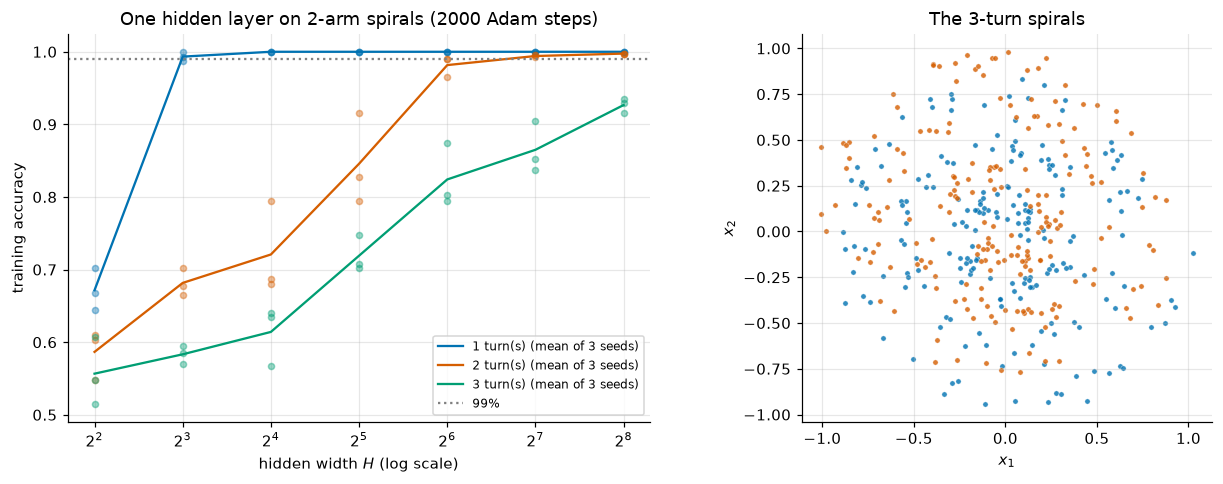

In [49]:
min_width_99 = {}
for turns in turns_list:
    min_width_99[turns] = next((w for w in widths if min(acc_ex4[turns, w]) >= 0.99), None)
print("smallest width with every seed >= 99%:", min_width_99)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for k, turns in enumerate(turns_list):
    accs_t = torch.tensor([acc_ex4[turns, w] for w in widths])                    # (len(widths), len(seeds))
    for s in range(len(seeds_ex4)):
        ax1.plot(widths, accs_t[:, s], "o", color=COLORS[k], alpha=0.4, ms=4)
    ax1.plot(widths, accs_t.mean(dim=1), "-", color=COLORS[k], label=f"{turns} turn(s) (mean of {len(seeds_ex4)} seeds)")
ax1.axhline(0.99, color="gray", ls=":", label="99%")
ax1.set_xscale("log", base=2)
ax1.set_xlabel("hidden width $H$ (log scale)")
ax1.set_ylabel("training accuracy")
ax1.set_title(f"One hidden layer on 2-arm spirals ({steps_ex4} Adam steps)")
ax1.legend(fontsize=8)
X_show, y_show = make_spirals(n=200, classes=2, turns=turns_list[-1], seed=0)
plot_dataset(X_show, y_show, ax=ax2, title=f"The {turns_list[-1]}-turn spirals")
plt.tight_layout()
plt.show()

In [50]:
check(isinstance(min_width_99, dict) and set(min_width_99) == set(turns_list), "min_width_99 should have one entry per number of turns")
for _t in turns_list:
    _ok = [w for w in widths if min(acc_ex4[_t, w]) >= 0.99]
    check(min_width_99[_t] == (_ok[0] if _ok else None), f"min_width_99[{_t}] = {min_width_99[_t]}, expected {_ok[0] if _ok else None}")
passed("Exercise 4 analysis")

✅ Exercise 4 analysis passed


*Your conclusion:*

> **Worked solution.**
>
> **Smallest width with all three seeds at ≥ 99%:** 1 turn — $H = 16$ ($H = 8$ already gives 0.988–1.000); 2 turns — $H = 128$ (0.993–0.995; $H = 64$ gives 0.965–0.990); 3 turns — none up to 256 (0.915–0.935 at $H = 256$).
>
> **Growth.** Each extra turn multiplied the required width by about 8 (16 → 128 → more than 256). That is fast, consistent with notebook 12: a one-hidden-layer ReLU network is a sum of $H$ hinge functions, and every extra turn adds more boundary crossings along every ray from the center, each needing its own linear pieces. Deeper networks can produce such repeated structure far more economically (notebook 12's tent maps; notebook 20).
>
> **What is measured.** Training accuracy after a fixed budget of 2000 Adam steps from one kind of initialization — what training *finds*, which is a lower bound on what each width *can represent*. Two signs that training matters: seeds disagree substantially at intermediate widths (e.g. 0.795–0.915 for 2 turns at $H = 32$), and the accuracy is still climbing with width at 3 turns. To separate the two, train longer (e.g. double `steps_ex4`) or with several learning rates and take the best run: if accuracy keeps improving, the earlier number was optimization-limited. Also, with noise 0.05 and 3 turns, the arms nearly touch, so reaching 100% there means memorizing noise — which says nothing about how well the network would classify new points (notebook 22).

## Summary and what's next

- An **MLP** alternates affine maps and ReLUs: $A^{(\ell)} = H^{(\ell-1)}W^{(\ell)\top} + \mathbf b^{(\ell)}$, $H^{(\ell)} = \operatorname{relu}(A^{(\ell)})$, with no ReLU on the output logits. $W^{(\ell)}$ has shape $(n_\ell, n_{\ell-1})$, activations $(N, n_\ell)$, and the parameter count is $\sum_\ell (n_{\ell-1}+1)\,n_\ell$ — 4547 for $2 \to 64 \to 64 \to 3$.
- Parameters are plain leaf tensors with `requires_grad=True` (scale first, then set `requires_grad`). The forward pass never mixes rows, so a batch of $N$ examples equals $N$ separate passes — and is far faster.
- Training = forward → `F.cross_entropy` → `backward()` → in-place update under `no_grad` → reset `.grad`. Our 4547-parameter MLP fits the spirals (97% training accuracy) where softmax regression is stuck at 45%.
- **Habit 1, initial loss:** at a sensible initialization $L \approx \ln K$ (we derived the expansion; over 20 seeds the loss stayed within 0.07 of $\ln 3$). The rule assumes nearly equal initial logits: a bug-free network with larger random weights starts far above $\ln K$, and imbalanced classes with a frequency-matched bias start legitimately below it. Weights scaled by $c$ scale a ReLU network's logits by $c^{\text{depth}}$; too large gives a loss ≫ $\ln K$ from confident wrong predictions, with the *same* accuracy.
- **Habit 2, overfit a tiny batch:** a working pipeline drives the loss on 12 examples to ≈ 0 in seconds. A buggy standardization that collapsed every input to two points could not get below a floor we computed exactly. The test catches information-destroying and no-learning bugs, not capacity-reducing ones. A failure is evidence, not proof: correct code with a tiny learning rate fails it too.
- **Habit 3, gradient norms per tensor:** healthy runs have comparable, finite, nonzero norms; `None`/zero, `nan`/`inf`, tiny, or steadily growing norms each point to a specific problem.
- `torch.optim` needs only an iterable of leaf tensors with `.grad`; it reproduced our update exactly. `nn.Sequential` with copied weights is the same network.

We called `loss.backward()` and trusted it. **Notebook 14** opens the box: it derives the gradients of a two-layer MLP by hand, in matrix form, verifies them against autograd and `gradcheck`, and explains why the gradient of a layer is multiplied by the weights above it — the mechanism behind the small-initialization slowdown we measured in Section 6.